# Audio-aware chord suggestion prototype
CREPE extracts a melody proxy and a trainable network ranks chord candidates. Scores are random until preference labels are supplied.

In [1]:
from pathlib import Path
import pandas as pd
import torch
from reharmonize_models import (ChordCandidateRanker, aggregate_melody_by_chord, melody_clash_score, melody_pitch_track)
ROOT = Path('..').resolve()
AUDIO = ROOT / 'vendor/BTC-ISMIR19/test/example.mp3'
assert AUDIO.exists()

In [2]:
# BTC output from its published large-vocabulary checkpoint.
# The repository package will expose direct BTC inference in the next milestone.
lab = ROOT / 'artifacts/example.lab'
if lab.exists():
    chords = pd.read_csv(lab, sep=r'\s+', names=['start','end','chord'])
else:
    chords = pd.DataFrame([(0., 2.685, 'N'), (2.685, 4.074, 'F#:7'), (4.074, 5.370, 'B:maj7')], columns=['start','end','chord'])
chords.head()

,start,end,chord
0,0.000,2.685,N
1,2.685,4.074,F#:7
2,4.074,5.370,B:maj7


/workspace/Reharmonize-Models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


mkdir -p failed for path /home/agent/.config/matplotlib: [Errno 30] Read-only file system: '/home/agent/.config/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-rjp22jo9 because there was an issue with the default path (/home/agent/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Fontconfig error: No writable cache directories


{'frames': 3001, 'voiced_fraction': 0.4241919360213262}


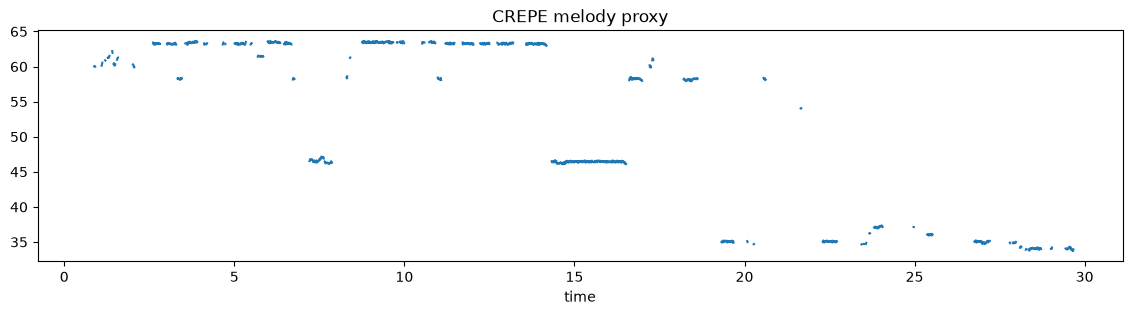

In [3]:
melody = melody_pitch_track(AUDIO, duration=30.0)
ax = melody.plot(x='time', y='midi', figsize=(14,3), legend=False, title='CREPE melody proxy')
print({'frames': len(melody), 'voiced_fraction': float(melody.midi.notna().mean())})

In [4]:
segments = aggregate_melody_by_chord(chords, melody)
segments['clash'] = segments.apply(lambda row: melody_clash_score(row.melody_profile, row.chord), axis=1)
segments[['start','end','chord','voiced_frames','clash']]

,start,end,chord,voiced_frames,clash
0,0.000,2.685,N,44,0.000000
1,2.685,4.074,F#:7,91,0.778483
2,4.074,5.370,B:maj7,46,0.021244


In [5]:
ranker = ChordCandidateRanker(context_size=557, candidate_size=44)
scores = ranker(torch.randn(8,557), torch.randn(8,44))
print({'scores_shape': tuple(scores.shape), 'parameters': sum(p.numel() for p in ranker.parameters())})

{'scores_shape': (8,), 'parameters': 160129}


## Next step
Train with preferred/rejected candidate pairs from licensed arrangements or musician feedback, split by song and artist.